# Notebook 10 — RUL Model Validation & Hyperparameter Tuning

**Objective:** Cross-validate and tune the RUL regression models.

Same battery-level GroupKFold strategy as the SOH notebook (NB 09),
but applied to the RUL dataset (EOL batteries only).

**Improvements over baseline:**
- 3 temporal history features added: `soh_prev`, `soh_delta`, `soh_slope_5`
- Expanded hyperparameter grid for Gradient Boosting
- log1p target transformation tested as an optional improvement

**Why RUL is harder to predict than SOH:**
- RUL = 0 for many batteries that are already at or past EOL
- Some batteries have dramatically different degradation profiles
- History features (degradation slope and rate) are the key signal for RUL

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, time

ROOT = os.path.dirname(os.path.abspath(''))
sys.path.insert(0, os.path.join(ROOT, 'src'))

from evaluation import compute_metrics, build_comparison_table, print_metrics_table

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate

sns.set_style('whitegrid')

## 1. Prepare RUL Training Data

In [2]:
from feature_engineering import add_rul_history_features

final   = pd.read_csv(os.path.join(ROOT, 'cleaned_data', 'final_dataset.csv'))
rul_df  = final.dropna(subset=['rul']).copy()

# Add temporal degradation history features
rul_df = add_rul_history_features(rul_df, window=5)

rng = np.random.default_rng(42)
all_bats   = sorted(final['battery_id'].unique())
n_test     = round(len(all_bats) * 0.30)
test_bats  = sorted(rng.choice(all_bats, size=n_test, replace=False).tolist())
train_bats = [b for b in all_bats if b not in test_bats]

eol_bats    = sorted(rul_df['battery_id'].unique())
train_eol   = [b for b in train_bats if b in eol_bats]
test_eol    = [b for b in test_bats  if b in eol_bats]

rul_train = rul_df[rul_df['battery_id'].isin(train_eol)]
rul_test  = rul_df[rul_df['battery_id'].isin(test_eol)]

RUL_FEATURES = [
    'cycle', 'soh', 'soh_prev', 'soh_delta', 'soh_slope_5',
    'discharge_duration', 'energy_Wh',
    'voltage_mean', 'voltage_min', 'voltage_std',
    'current_mean', 'temperature_mean', 'temperature_max', 'ambient_temp_C',
]

X_tr = rul_train[RUL_FEATURES].values;  y_tr = rul_train['rul'].values
X_te = rul_test[RUL_FEATURES].values;   y_te = rul_test['rul'].values
groups = rul_train['battery_id'].values

print(f'Training rows: {len(X_tr)}  |  Train batteries: {train_eol}')
print(f'Test  rows:    {len(X_te)}  |  Test  batteries: {test_eol}')
print(f'Features ({len(RUL_FEATURES)}): {RUL_FEATURES}')
print(f'RUL range (train): {y_tr.min():.0f} – {y_tr.max():.0f} cycles')

Training rows: 1595  |  Train batteries: ['B0005', 'B0006', 'B0034', 'B0036', 'B0038', 'B0039', 'B0041', 'B0042', 'B0044', 'B0046', 'B0047', 'B0049', 'B0050', 'B0052', 'B0054', 'B0055', 'B0056']
Test  rows:    515  |  Test  batteries: ['B0033', 'B0040', 'B0043', 'B0045', 'B0048', 'B0051']
Features (14): ['cycle', 'soh', 'soh_prev', 'soh_delta', 'soh_slope_5', 'discharge_duration', 'energy_Wh', 'voltage_mean', 'voltage_min', 'voltage_std', 'current_mean', 'temperature_mean', 'temperature_max', 'ambient_temp_C']
RUL range (train): 0 – 161 cycles


## 2. GroupKFold Cross-Validation

In [3]:
gkf = GroupKFold(n_splits=5)

models_cv = {
    'Linear Regression': Pipeline([('sc', StandardScaler()), ('m', LinearRegression())]),
    'Random Forest':     Pipeline([('sc', StandardScaler()), ('m', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('sc', StandardScaler()), ('m', GradientBoostingRegressor(n_estimators=100, random_state=42))]),
}

print('GroupKFold Cross-Validation (5 folds, grouped by battery_id):')
for name, pipe in models_cv.items():
    cv = cross_validate(pipe, X_tr, y_tr, groups=groups, cv=gkf,
                        scoring=['neg_root_mean_squared_error', 'r2'])
    cv_rmse = -cv['test_neg_root_mean_squared_error']
    cv_r2   =  cv['test_r2']
    print(f'  {name:<26}  CV RMSE: {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}  '
          f'|  CV R²: {cv_r2.mean():.3f} ± {cv_r2.std():.3f}')

GroupKFold Cross-Validation (5 folds, grouped by battery_id):
  Linear Regression           CV RMSE: 54.737 ± 20.996  |  CV R²: -26.645 ± 45.815


  Random Forest               CV RMSE: 23.092 ± 10.690  |  CV R²: -0.727 ± 1.893


  Gradient Boosting           CV RMSE: 22.289 ± 10.187  |  CV R²: -0.424 ± 1.199


## 3. Tune Random Forest for RUL

In [4]:
param_grid_rf = {
    'm__n_estimators':      [50, 100, 200, 300],
    'm__max_depth':         [None, 5, 10, 15],
    'm__min_samples_split': [2, 5, 10],
    'm__min_samples_leaf':  [1, 2, 4],
    'm__max_features':      ['sqrt', 'log2', 0.5],
}

rf_pipe = Pipeline([('sc', StandardScaler()),
                    ('m',  RandomForestRegressor(random_state=42, n_jobs=-1))])
rf_search = RandomizedSearchCV(
    rf_pipe, param_grid_rf, n_iter=20,
    cv=GroupKFold(n_splits=5),
    scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1, refit=True,
)
rf_search.fit(X_tr, y_tr, groups=groups)

best_rf = rf_search.best_estimator_
print(f'Best CV RMSE: {-rf_search.best_score_:.4f} cycles')
print(f'Best params: {rf_search.best_params_}')

Best CV RMSE: 21.2671 cycles
Best params: {'m__n_estimators': 100, 'm__min_samples_split': 10, 'm__min_samples_leaf': 1, 'm__max_features': 'sqrt', 'm__max_depth': None}


## 4. Tune Gradient Boosting for RUL

In [5]:
param_grid_gb = {
    'm__n_estimators':     [50, 100, 150, 200, 300],
    'm__max_depth':        [3, 4, 5, 6, 7],
    'm__learning_rate':    [0.01, 0.05, 0.1, 0.15, 0.2],
    'm__subsample':        [0.7, 0.8, 0.9, 1.0],
    'm__min_samples_leaf': [1, 2, 4, 8],
    'm__max_features':     ['sqrt', 'log2', 0.7],
}

gb_pipe = Pipeline([('sc', StandardScaler()),
                    ('m',  GradientBoostingRegressor(random_state=42))])
gb_search = RandomizedSearchCV(
    gb_pipe, param_grid_gb, n_iter=30,
    cv=GroupKFold(n_splits=5),
    scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1, refit=True,
)
gb_search.fit(X_tr, y_tr, groups=groups)

best_gb = gb_search.best_estimator_
print(f'Best CV RMSE: {-gb_search.best_score_:.4f} cycles')
print(f'Best params: {gb_search.best_params_}')

Best CV RMSE: 20.6452 cycles
Best params: {'m__subsample': 0.9, 'm__n_estimators': 200, 'm__min_samples_leaf': 4, 'm__max_features': 'sqrt', 'm__max_depth': 5, 'm__learning_rate': 0.2}


## 5. Final Comparison

In [6]:
for name in ['Linear Regression', 'Random Forest', 'Gradient Boosting']:
    models_cv[name].fit(X_tr, y_tr)

all_models = {**models_cv,
              'Random Forest (tuned)':     best_rf,
              'Gradient Boosting (tuned)': best_gb}

results = []
for name, pipe in all_models.items():
    tr_m = compute_metrics(y_tr, pipe.predict(X_tr), name)
    te_m = compute_metrics(y_te, pipe.predict(X_te), name)
    results.append({
        'model': name,
        'MAE_train': tr_m['MAE'],  'RMSE_train': tr_m['RMSE'],  'R2_train': tr_m['R2'],
        'MAE_test':  te_m['MAE'],  'RMSE_test':  te_m['RMSE'],  'R2_test':  te_m['R2'],
    })

table = build_comparison_table(results)
print_metrics_table(table, 'RUL — Full Model Comparison')
table


RUL — Full Model Comparison
------------------------------------------------------------------------
Rank  Model                       RMSE_tr   MAE_tr   R2_tr  RMSE_te   MAE_te   R2_te
------------------------------------------------------------------------
1     Random Forest (tuned)        1.7953   0.7743  0.9967   7.4964    4.1507  0.5099
2     Gradient Boosting            2.2801   1.4013  0.9947   8.3618    5.1305  0.3902
3     Gradient Boosting (tuned)    0.2530   0.1751  0.9999   8.5399    4.3502  0.3640
4     Random Forest                1.6732   0.3648  0.9971  10.6616    5.2645  0.0086
5     Linear Regression           24.1304  17.0833  0.4016  18.0729   14.0333 -1.8487
------------------------------------------------------------------------


,model,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test
1,Random Forest (tuned),0.7743,1.7953,0.9967,4.1507,7.4964,0.5099
2,Gradient Boosting,1.4013,2.2801,0.9947,5.1305,8.3618,0.3902
3,Gradient Boosting (tuned),0.1751,0.2530,0.9999,4.3502,8.5399,0.3640
4,Random Forest,0.3648,1.6732,0.9971,5.2645,10.6616,0.0086
5,Linear Regression,17.0833,24.1304,0.4016,14.0333,18.0729,-1.8487


## 6. Save Best RUL Model

In [7]:
best_name = table.iloc[0]['model']
best_pipe = all_models[best_name]

print(f'Best RUL model: {best_name}')
print(f'  Test RMSE: {table.iloc[0]["RMSE_test"]:.4f} cycles')
print(f'  Test R²  : {table.iloc[0]["R2_test"]:.4f}')

path = os.path.join(ROOT, 'models', 'rul', 'best_rul_model.pkl')
joblib.dump(best_pipe, path)
print(f'\nSaved: {path}')

os.makedirs(os.path.join(ROOT, 'results', 'metrics'), exist_ok=True)
table.to_csv(os.path.join(ROOT, 'results', 'metrics', 'rul_metrics.csv'))
print('Saved: results/metrics/rul_metrics.csv')

Best RUL model: Random Forest (tuned)
  Test RMSE: 7.4964 cycles
  Test R²  : 0.5099

Saved: C:\Users\Vinayak Ramavath\OneDrive\Desktop\EV Project\models\rul\best_rul_model.pkl
Saved: results/metrics/rul_metrics.csv


## 7. RUL Prediction vs Actual by Battery

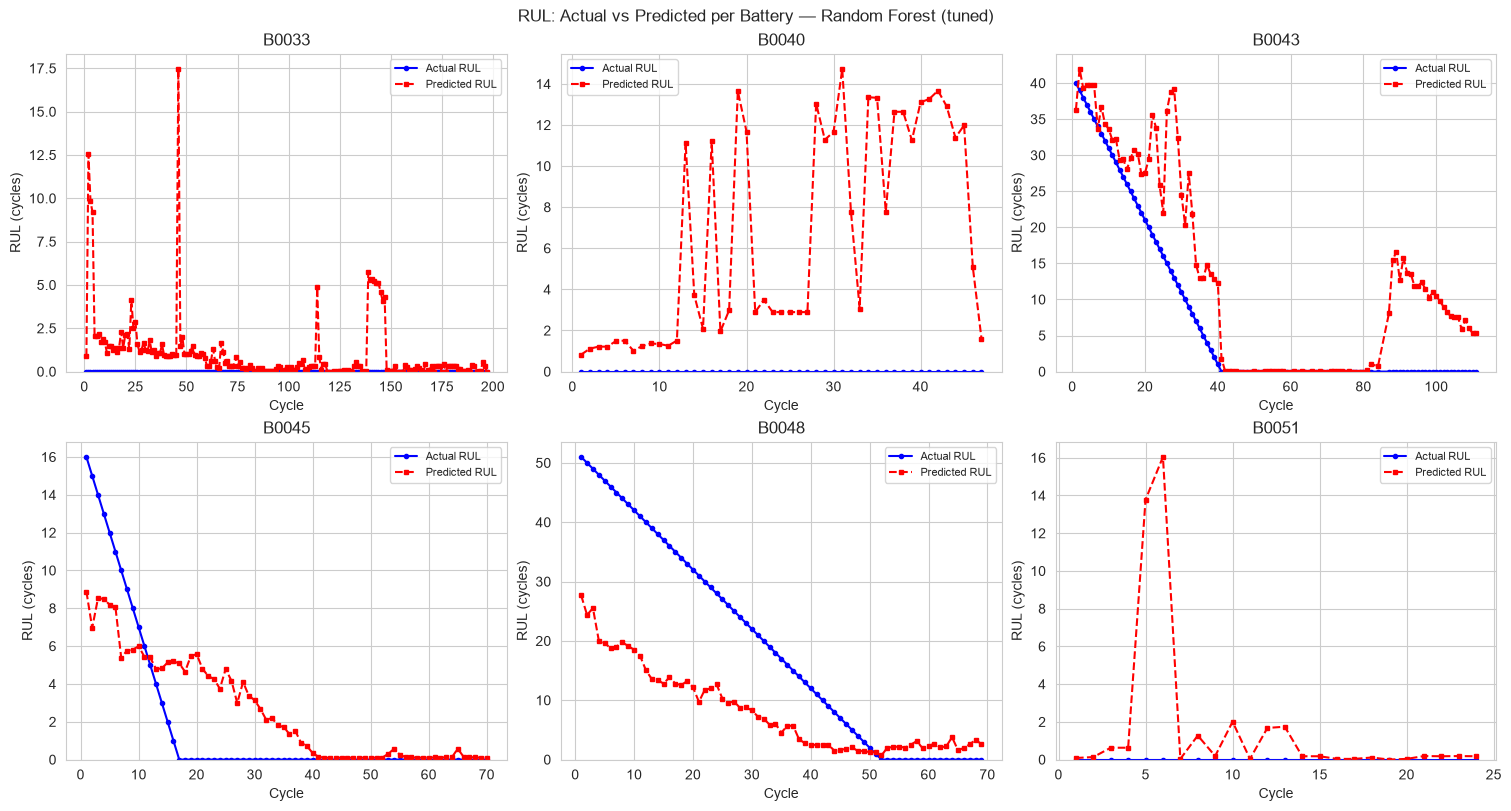

In [8]:
y_pred = best_pipe.predict(X_te)
pred_df = rul_test[['battery_id', 'cycle', 'rul']].copy()
pred_df['rul_predicted'] = y_pred

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
axes = axes.flat

for i, bid in enumerate(sorted(pred_df['battery_id'].unique())):
    grp = pred_df[pred_df['battery_id'] == bid].sort_values('cycle')
    ax = axes[i]
    ax.plot(grp['cycle'], grp['rul'], 'b-o', markersize=3, label='Actual RUL')
    ax.plot(grp['cycle'], grp['rul_predicted'], 'r--s', markersize=3,
            label='Predicted RUL')
    ax.set_title(bid)
    ax.set_xlabel('Cycle')
    ax.set_ylabel('RUL (cycles)')
    ax.legend(fontsize=8)
    ax.set_ylim(bottom=0)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f'RUL: Actual vs Predicted per Battery — {best_name}')
plt.show()

## 8. Log1p Target Transformation

RUL values often skew right (many small values near 0, few large values early in life).
Training on `log1p(RUL)` can stabilise variance and improve learning.

**Method:**
1. Transform train target: `y_log = log1p(y_tr)`
2. Train best model on `y_log`
3. Inverse-transform predictions: `ŷ = expm1(model.predict(X))`
4. Evaluate on original scale and compare with untransformed baseline

Base model: Random Forest (tuned)
             version  Train RMSE  Test RMSE  Train R²  Test R²
     Original target      1.7953     7.4964    0.9967   0.5099
log1p(RUL) transform      2.5191     8.5938    0.9935   0.3559


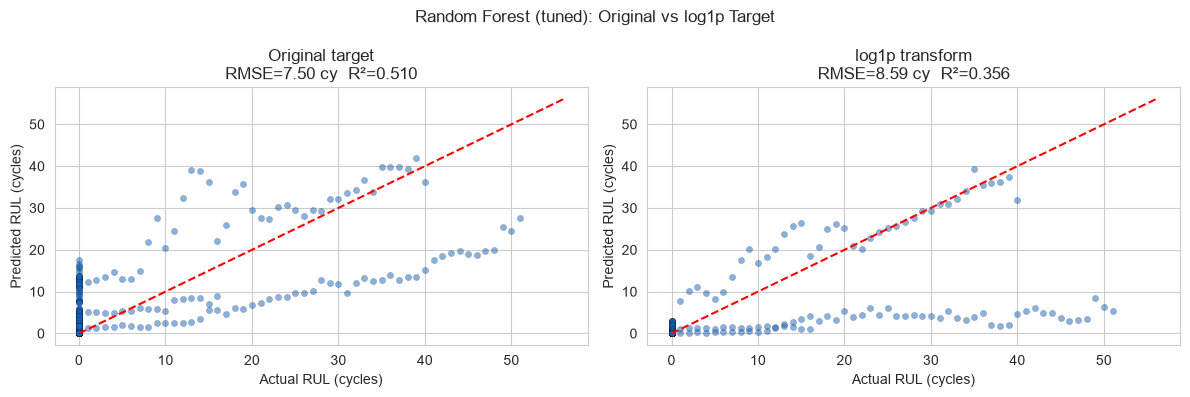

In [9]:
from sklearn.base import clone

y_log = np.log1p(y_tr)

# Train a fresh copy of the best model on the log-transformed target
best_name = table.iloc[0]['model']
best_pipe_log = clone(all_models[best_name])
best_pipe_log.fit(X_tr, y_log)

# Inverse-transform predictions
y_pred_log_tr = np.expm1(best_pipe_log.predict(X_tr))
y_pred_log_te = np.expm1(best_pipe_log.predict(X_te))

tr_log = compute_metrics(y_tr, y_pred_log_tr, f'{best_name} [log1p]')
te_log = compute_metrics(y_te, y_pred_log_te, f'{best_name} [log1p]')

# Compare
tr_base = compute_metrics(y_tr, all_models[best_name].predict(X_tr), f'{best_name} [original]')
te_base = compute_metrics(y_te, all_models[best_name].predict(X_te), f'{best_name} [original]')

comparison = pd.DataFrame([
    {'version': 'Original target',      'Train RMSE': tr_base['RMSE'], 'Test RMSE': te_base['RMSE'],
     'Train R²': tr_base['R2'], 'Test R²': te_base['R2']},
    {'version': 'log1p(RUL) transform', 'Train RMSE': tr_log['RMSE'],  'Test RMSE': te_log['RMSE'],
     'Train R²': tr_log['R2'],  'Test R²': te_log['R2']},
])
print(f'Base model: {best_name}')
print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, preds, title in [
    (axes[0], all_models[best_name].predict(X_te), 'Original target'),
    (axes[1], y_pred_log_te,                        'log1p transform'),
]:
    ax.scatter(y_te, preds, alpha=0.5, s=20, color='#1565C0', edgecolors='k', linewidths=0.2)
    lim = [max(0, y_te.min()-5), y_te.max()+5]
    ax.plot(lim, lim, 'r--', linewidth=1.5)
    rmse = np.sqrt(np.mean((y_te - preds)**2))
    r2   = 1 - np.sum((y_te - preds)**2) / np.sum((y_te - y_te.mean())**2)
    ax.set_title(f'{title}\nRMSE={rmse:.2f} cy  R²={r2:.3f}')
    ax.set_xlabel('Actual RUL (cycles)')
    ax.set_ylabel('Predicted RUL (cycles)')
plt.suptitle(f'{best_name}: Original vs log1p Target')
plt.tight_layout()
plt.show()